In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import glob

from micom import load_pickle
from micom.qiime_formats import load_qiime_model_db, load_qiime_medium
from micom.workflows import grow, save_results, load_results
from micom.viz import *
from micom.measures import *

cmap = sns.color_palette("coolwarm_r", as_cmap=True)

In [2]:
taxa = [
    'B_caccae',
    'B_cellulosilyticus_WH2',
    'B_ovatus',
    'B_thetaiotaomicron',
    'B_uniformis',
    'B_vulgatus',
    'C_aerofaciens',
    'C_scindens',
    'C_spiroforme',
    'P_distasonis',
    'R_obeum'
    ]

pretty_names_dir = {
    'B_caccae': 'Bca',
    'B_cellulosilyticus_WH2': 'Bce',
    'B_ovatus': 'Bov',
    'B_thetaiotaomicron': 'Bth',
    'B_uniformis': 'Bun',
    'B_vulgatus': 'Bvu',
    'C_aerofaciens': 'Cae',
    'C_scindens': 'Csc',
    'C_spiroforme': 'Csp',
    'P_distasonis': 'Pdi',
    'R_obeum': 'Rob',
    }

# LF0

In [3]:
diet = load_qiime_medium("media/vmh_high_fiber.qza")
ko_log_foldchange = []
for file_path in glob.glob("models/Community/lf0/*.pickle"):
    name = file_path.split("/")[-1].split(".")[0]
    com = load_pickle(file_path)
    com.medium = diet.flux
    ko_new, ko_old = com.knockout_taxa(fraction=0.6, method='raw', diag=False)
    ko_old = ko_old.drop('medium', axis=0)
    old = np.zeros(ko_new.shape)
    for ko in range(len(ko_new.index)):
        for taxa in range(len(ko_old.index)):
            old[ko, taxa] = ko_old.iloc[taxa]
            if ko == taxa:
                old[ko, taxa] = np.nan
    old = pd.DataFrame(old, index=ko_new.index, columns=ko_old.index)
    ko_log_foldchange.append(-(np.log10(ko_new+1e-6) - np.log10(old+1e-6)))

Set parameter Username
Academic license - for non-commercial use only - expires 2024-10-23
Read LP format model from file /tmp/tmpobz99a6g.lp
Reading time = 0.14 seconds
: 16186 rows, 48895 columns, 186527 nonzeros


Output()

Read LP format model from file /tmp/tmpgk7h1s04.lp
Reading time = 0.11 seconds
: 16186 rows, 48895 columns, 186527 nonzeros


Output()

Read LP format model from file /tmp/tmph0_l_qbf.lp
Reading time = 0.14 seconds
: 16186 rows, 48895 columns, 186527 nonzeros


Output()

... (4 outputs left out)

Read LP format model from file /tmp/tmp41az2fhw.lp
Reading time = 0.12 seconds
: 16186 rows, 48895 columns, 186527 nonzeros


Output()

Read LP format model from file /tmp/tmpqtqlglmd.lp
Reading time = 0.17 seconds
: 16186 rows, 48895 columns, 186527 nonzeros


Output()

In [4]:
ko_log_foldchange_mean = pd.DataFrame(
    np.mean(ko_log_foldchange, axis=0), 
    columns=ko_log_foldchange[0].columns, 
    index=ko_log_foldchange[0].index
    )
ko_log_foldchange_mean.index.name = 'Knockout species'
ko_log_foldchange_mean.columns.name = 'Species'
ko_log_foldchange_mean.to_csv("results/lf0/knockouts/ko_foldchange_mean.tsv", sep="\t")
ko_log_foldchange_mean.columns = ko_log_foldchange_mean.columns.map(pretty_names_dir)
ko_log_foldchange_mean.index = ko_log_foldchange_mean.index.map(pretty_names_dir)
ko_log_foldchange_mean

Species,Bca,Bce,Bov,Bth,Bun,Bvu,Cae,Csc,Csp,Pdi,Rob
Knockout species,,,,,,,,,,,
Bca,NaN,-1.302355,0.096843,0.002133,-8.566700e-01,0.001427,-7.912619e-01,-0.512651,-2.227754,-0.019757,-1.127870e+00
Bce,-3.275503e+00,NaN,-2.954304,-0.003065,-3.136423e+00,-0.003215,-1.941518e+00,-1.893029,-1.866640,-0.005838,-3.013382e+00
Bov,-2.644060e-01,-1.321070,NaN,0.000557,-2.556159e-01,0.000334,-4.603472e-01,-0.203252,-0.608897,-0.004514,-5.796341e-01
Bth,-2.991706e-05,0.008046,0.565012,NaN,-6.872732e-01,-0.250017,-1.149460e-04,0.127274,-0.019596,-0.250117,-1.925344e-04
Bun,-9.856733e-01,-1.208936,-0.106063,3.720056,NaN,3.748554,-1.120296e+00,-0.899828,-1.796735,3.118173,-1.172660e+00
Bvu,-2.192268e-02,0.012146,-0.949176,-0.326166,-2.310660e-02,NaN,-2.543014e-02,0.110274,-0.319275,-0.326313,-2.834798e-02
Cae,-4.882003e-01,-0.646758,0.715147,-0.094299,-6.021240e-01,1.421815,NaN,-0.367789,-0.694205,1.229555,-5.771947e-01
Csc,-1.707787e-01,-1.306842,1.389893,0.008743,-1.589212e-01,0.011597,-3.244878e-01,NaN,-0.527122,-0.077187,-4.432175e-01
Csp,3.702144e-07,-0.653310,1.280586,0.000005,1.738091e-07,0.000005,1.677282e-07,0.127313,NaN,0.000005,2.232229e-07


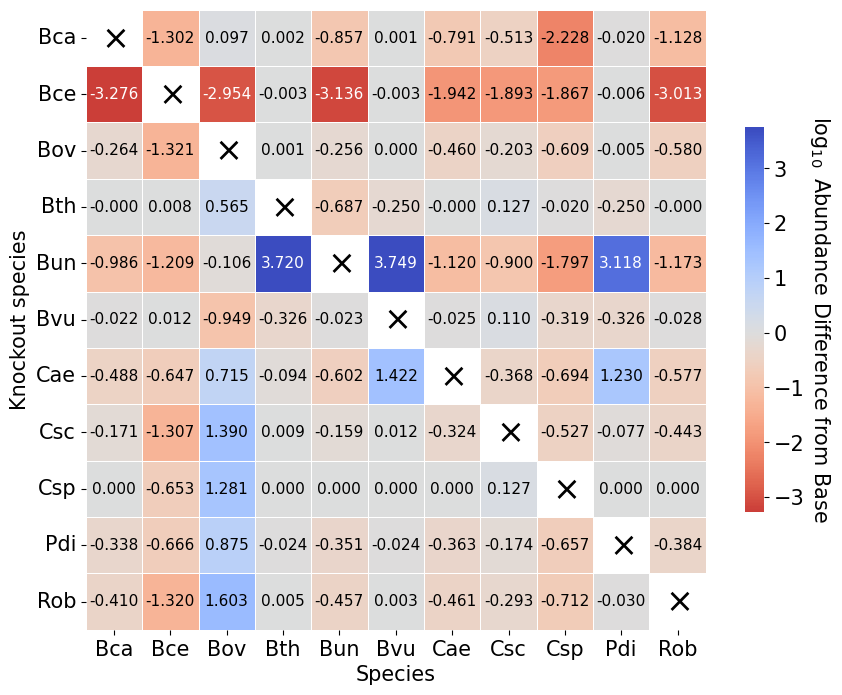

In [5]:
mask = ko_log_foldchange_mean.isna()
plt.rc('font', size=15)
cmap = sns.color_palette("coolwarm_r", as_cmap=True)
plt.figure(figsize=(10,10))
ax = sns.heatmap(
    ko_log_foldchange_mean, 
    cmap=cmap, 
    mask=mask, 
    center=0, 
    square=True, 
    cbar_kws={"shrink": .5}, 
    linewidths=0.5,
    linecolor='w',
    # annot=True,
    # fmt='.3f',
    annot_kws={'size': 11}
    )
for i in range(mask.shape[0]):
    for j in range(mask.shape[1]):
        if mask.iloc[i,j] == True:
            plt.text(j+0.5, i+0.5, '$\\times$', ha='center', va='center', color='k', fontsize=24)
        else:
            if np.abs(ko_log_foldchange_mean.iloc[i,j]) > 2.5:
                plt.text(j+0.5, i+0.5, f'{ko_log_foldchange_mean.iloc[i,j]:.3f}', ha='center', va='center', color='w', fontsize=11)
            else:
                plt.text(j+0.5, i+0.5, f'{ko_log_foldchange_mean.iloc[i,j]:.3f}', ha='center', va='center', color='k', fontsize=11)
cbar = ax.collections[0].colorbar
cbar.set_label('$\log_{10}$ Abundance Difference from Base', rotation=270, fontsize=15, labelpad=20)
ax.set_xticklabels(ax.get_xticklabels(), ha='center')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, ha='right')
plt.savefig("results/lf0/knockouts/ko_foldchange_mean.svg", bbox_inches='tight', dpi=300)
plt.show()